In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from PIL import Image


In [ ]:
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\Lenovo\Desktop\multi class animal classification\animals 10 dataset\raw-img"
)

print("Dataset exists:", DATA_DIR.exists())
print("Animal classes:", [folder.name for folder in DATA_DIR.iterdir() if folder.is_dir()])

Dataset exists: True
Animal classes: ['dog', 'horse', 'elephant', 'butterfly', 'chicken', 'cat', 'cow', 'sheep', 'spider', 'squirrel']


In [4]:
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = {}

for folder in DATA_DIR.iterdir():
    if folder.is_dir():
        count = sum(
            1 for file in folder.rglob("*")
            if file.suffix.lower() in image_extensions
        )
        class_counts[folder.name] = count

for animal, count in sorted(class_counts.items()):
    print(f"{animal:12s}: {count}")

print("\nTotal images:", sum(class_counts.values()))

butterfly   : 2112
cat         : 1668
chicken     : 3098
cow         : 1866
dog         : 4863
elephant    : 1446
horse       : 2623
sheep       : 1820
spider      : 4821
squirrel    : 1862

Total images: 26179


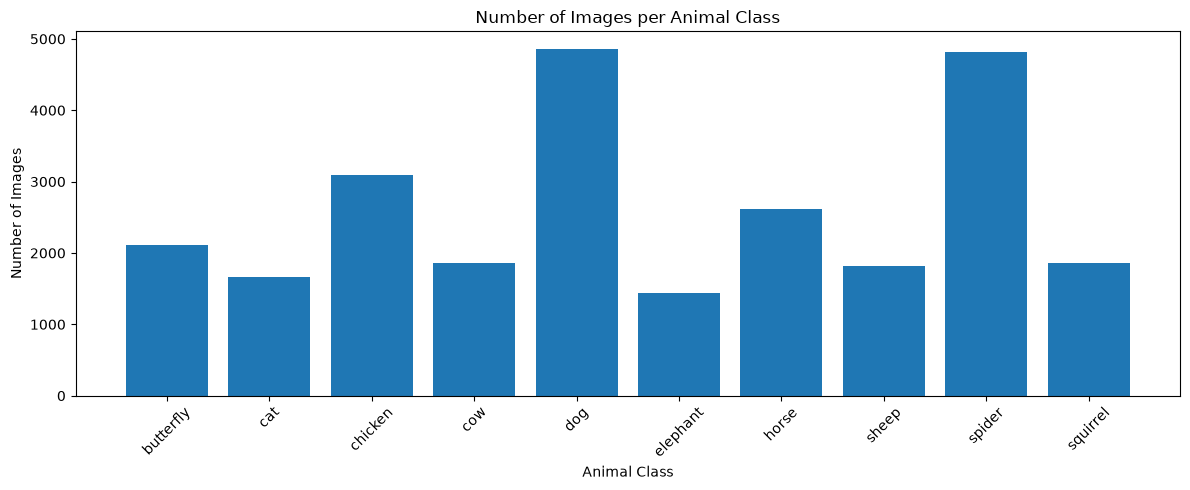

In [5]:
animals = list(class_counts.keys())
counts = list(class_counts.values())

plt.figure(figsize=(12, 5))
plt.bar(animals, counts)
plt.title("Number of Images per Animal Class")
plt.xlabel("Animal Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
import pandas as pd

records = []

for animal in sorted(class_counts.keys()):
    folder = DATA_DIR / animal

    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() in image_extensions:
            records.append({
                "filepath": str(file),
                "label": animal
            })

df = pd.DataFrame(records)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Total:", len(df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Total: 26179
Training: 18325
Validation: 3927
Test: 3927


In [7]:
print("Training class counts:")
print(train_df["label"].value_counts())


Training class counts:
label
dog          3404
spider       3375
chicken      2169
horse        1836
butterfly    1478
cow          1306
squirrel     1303
sheep        1274
cat          1168
elephant     1012
Name: count, dtype: int64


In [8]:
import tensorflow as tf

class_names = sorted(df["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print(class_to_index)

{'butterfly': 0, 'cat': 1, 'chicken': 2, 'cow': 3, 'dog': 4, 'elephant': 5, 'horse': 6, 'sheep': 7, 'spider': 8, 'squirrel': 9}


In [9]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [10]:
def create_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].to_numpy()

    labels = dataframe["label"].map(
        class_to_index
    ).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets created successfully.")

Datasets created successfully.


In [11]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", tf.reduce_min(images).numpy(),
      "to", tf.reduce_max(images).numpy())
print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0
First 10 labels: [6 1 6 8 4 8 1 4 2 7]


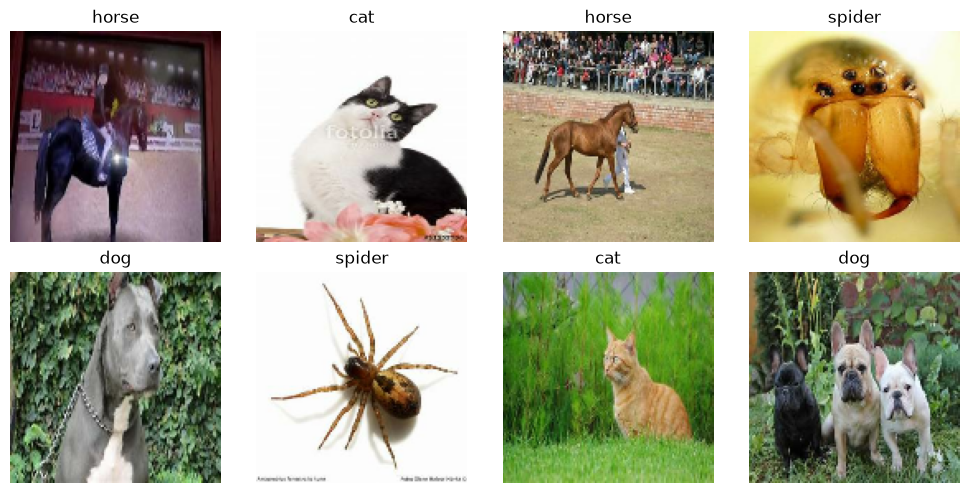

In [12]:
plt.figure(figsize=(10, 5))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import time

def prepare_rf_data(dataframe):
    X, y = [], []

    for filepath, label in zip(
        dataframe["filepath"], dataframe["label"]
    ):
        image = tf.io.read_file(filepath)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image = tf.image.resize(image, (32, 32)).numpy()

        X.append(image.flatten())
        y.append(class_to_index[label])

    return np.array(X), np.array(y)

X_train_rf, y_train_rf = prepare_rf_data(train_df)
X_test_rf, y_test_rf = prepare_rf_data(test_df)

print("Baseline training shape:", X_train_rf.shape)
print("Baseline test shape:", X_test_rf.shape)

Baseline training shape: (18325, 3072)
Baseline test shape: (3927, 3072)


In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf_model.fit(X_train_rf, y_train_rf)
rf_train_time = time.time() - start

rf_predictions = rf_model.predict(X_test_rf)

rf_accuracy = accuracy_score(y_test_rf, rf_predictions)
rf_f1 = f1_score(y_test_rf, rf_predictions, average="macro")

print(f"Random Forest accuracy: {rf_accuracy:.4f}")
print(f"Random Forest macro F1: {rf_f1:.4f}")
print(f"Training time: {rf_train_time:.1f} seconds")

Random Forest accuracy: 0.4110
Random Forest macro F1: 0.3365
Training time: 83.1 seconds


In [15]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


573/573 ━━━━━━━━━━━━━━━━━━━━ 299s 515ms/step - accuracy: 0.3179 - loss: 1.9476 - val_accuracy: 0.4568 - val_loss: 1.6017
Epoch 2/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 335s 538ms/step - accuracy: 0.4600 - loss: 1.5613 - val_accuracy: 0.5404 - val_loss: 1.3671
Epoch 3/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 284s 495ms/step - accuracy: 0.5264 - loss: 1.3680 - val_accuracy: 0.5653 - val_loss: 1.2816
Epoch 4/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 225s 392ms/step - accuracy: 0.5746 - loss: 1.2225 - val_accuracy: 0.5992 - val_loss: 1.2569
Epoch 5/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 273s 412ms/step - accuracy: 0.6219 - loss: 1.0889 - val_accuracy: 0.6361 - val_loss: 1.1109
Epoch 6/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 255s 445ms/step - accuracy: 0.6578 - loss: 0.9799 - val_accuracy: 0.6458 - val_loss: 1.0937
Epoch 7/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 245s 415ms/step - accuracy: 0.6954 - loss: 0.8643 - val_accuracy: 0.6504 - val_loss: 1.1032
Epoch 8/15
573/573 ━━━━━━━━━━━━━━━━━━━━ 236s 412ms/step - accuracy: 0.7262 - loss: 0.77

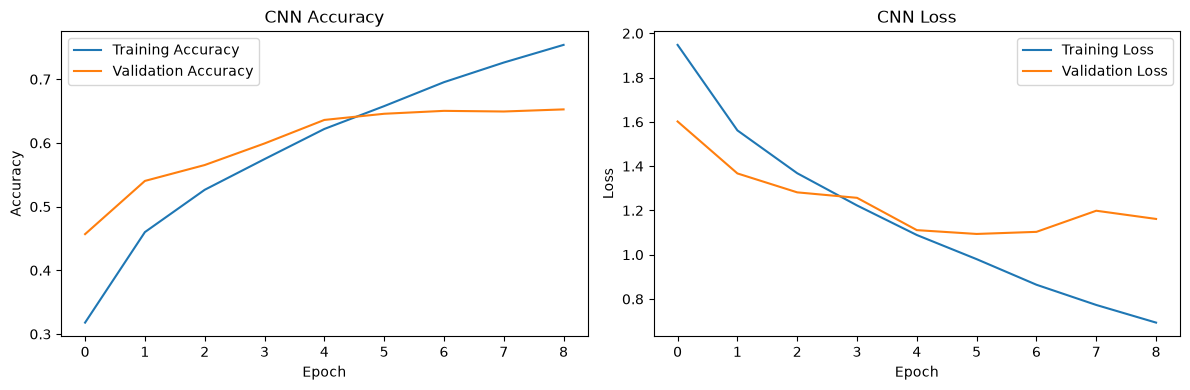

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = cnn_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

cnn_accuracy = accuracy_score(y_true, y_pred)
cnn_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
cnn_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
cnn_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print(f"CNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"CNN Macro Precision: {cnn_precision:.4f}")
print(f"CNN Macro Recall: {cnn_recall:.4f}")
print(f"CNN Macro F1-score: {cnn_f1:.4f}")

123/123 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step
CNN Test Accuracy: 0.6608
CNN Macro Precision: 0.6542
CNN Macro Recall: 0.5986
CNN Macro F1-score: 0.6136


In [19]:
from sklearn.metrics import classification_report

print("Random Forest Test Accuracy:", accuracy_score(
    y_test_rf, rf_predictions
))

print("Random Forest Macro F1:", f1_score(
    y_test_rf, rf_predictions,
    average="macro",
    zero_division=0
))

Random Forest Test Accuracy: 0.4110007639419404
Random Forest Macro F1: 0.3365011748005508


In [20]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest", "CNN"],
    "Test Accuracy": [
        accuracy_score(y_test_rf, rf_predictions),
        cnn_accuracy
    ],
    "Macro F1-score": [
        f1_score(y_test_rf, rf_predictions,
                 average="macro", zero_division=0),
        cnn_f1
    ]
})

comparison["Test Accuracy (%)"] = (
    comparison["Test Accuracy"] * 100
).round(2)

comparison["Macro F1-score (%)"] = (
    comparison["Macro F1-score"] * 100
).round(2)

display(comparison)

,Model,Test Accuracy,Macro F1-score,Test Accuracy (%),Macro F1-score (%)
0,Random Forest,0.411001,0.336501,41.10,33.65
1,CNN,0.660810,0.613619,66.08,61.36


In [21]:
improvement = (
    comparison.loc[1, "Test Accuracy"]
    - comparison.loc[0, "Test Accuracy"]
) * 100

print(f"CNN accuracy improvement: {improvement:.2f} percentage points")

CNN accuracy improvement: 24.98 percentage points


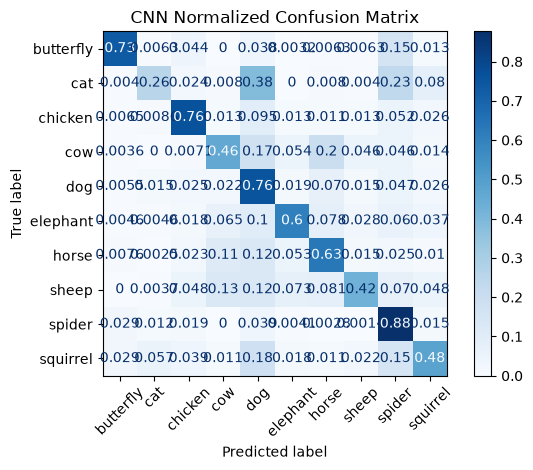

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true"
)

plt.title("CNN Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

   butterfly       0.85      0.73      0.79       317
         cat       0.59      0.26      0.36       250
     chicken       0.80      0.76      0.78       465
         cow       0.52      0.46      0.49       280
         dog       0.59      0.76      0.66       729
    elephant       0.61      0.60      0.61       217
       horse       0.61      0.63      0.62       394
       sheep       0.69      0.42      0.53       273
      spider       0.71      0.88      0.78       723
    squirrel       0.59      0.48      0.53       279

    accuracy                           0.66      3927
   macro avg       0.65      0.60      0.61      3927
weighted avg       0.66      0.66      0.65      3927



In [24]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "animal_cnn.keras"

cnn_model.save(model_path)

print("Model saved to:", model_path)

Model saved to: c:\Users\Lenovo\Desktop\multi class animal classification\models\animal_cnn.keras


In [25]:
import json

class_path = MODEL_DIR / "class_names.json"

with open(class_path, "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved.")
print(class_names)

Class names saved.
['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


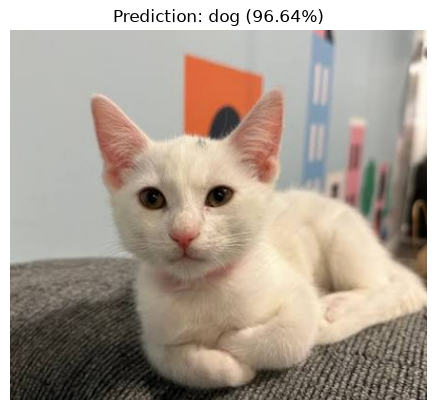

Predicted animal: dog
Model confidence: 96.64%


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

image_path = r"C:\Users\Lenovo\Pictures\Screenshots\test_1.png"

img = load_img(image_path, target_size=(128, 128))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

probabilities = cnn_model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(probabilities)
predicted_animal = class_names[predicted_index]
confidence = probabilities[predicted_index] * 100

plt.imshow(load_img(image_path))
plt.axis("off")
plt.title(
    f"Prediction: {predicted_animal} ({confidence:.2f}%)"
)
plt.show()

print("Predicted animal:", predicted_animal)
print(f"Model confidence: {confidence:.2f}%")

In [30]:
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("Comparison results saved.")

Comparison results saved.


In [31]:
plt.savefig(
    results_dir / "cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [32]:
print(list(results_dir.iterdir()))

[WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/cnn_classification_report.csv'), WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/cnn_confusion_matrix.png'), WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/cnn_training_curves.png'), WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/model_comparison.csv')]


In [33]:
from pathlib import Path
import json
import pandas as pd
from sklearn.metrics import classification_report

PROJECT_DIR = Path.cwd()
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained CNN
cnn_model.save(MODEL_DIR / "animal_cnn.keras")

# Save class names in the correct prediction order
with open(MODEL_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

# Save model comparison
comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

# Save detailed CNN evaluation
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "cnn_classification_report.csv"
)

print("Model, labels, and evaluation results saved.")
print("Model:", MODEL_DIR / "animal_cnn.keras")
print("Results:", list(RESULTS_DIR.iterdir()))

Model, labels, and evaluation results saved.
Model: c:\Users\Lenovo\Desktop\multi class animal classification\models\animal_cnn.keras
Results: [WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/cnn_classification_report.csv'), WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/cnn_confusion_matrix.png'), WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/cnn_training_curves.png'), WindowsPath('c:/Users/Lenovo/Desktop/multi class animal classification/results/model_comparison.csv')]


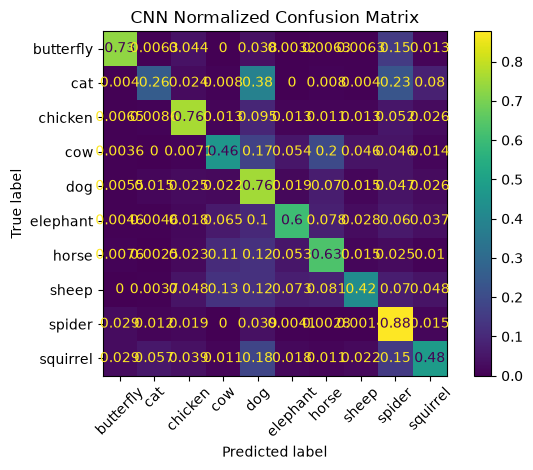

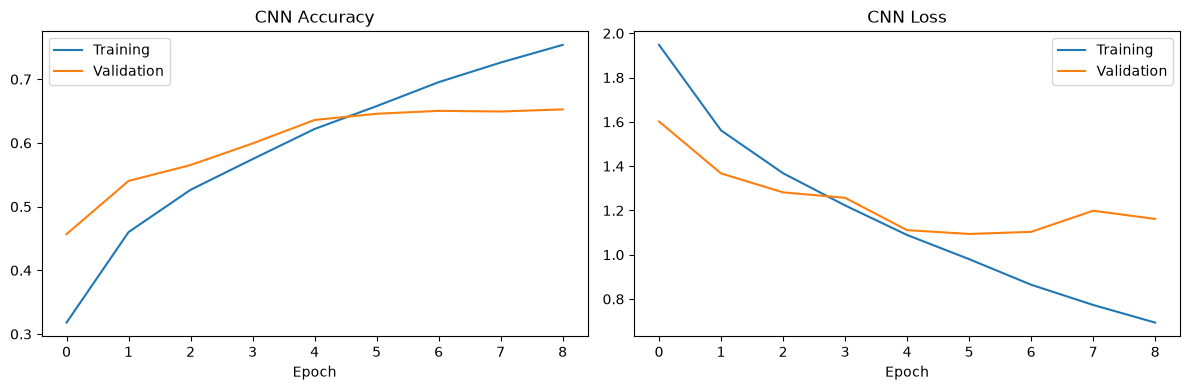

Plots saved.


In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    xticks_rotation=45,
    normalize="true"
)

plt.title("CNN Normalized Confusion Matrix")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "cnn_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Plots saved.")